[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/lifecycle/10-tuning.ipynb)

# Tuning and Experiment Tracking

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Search for better settings without spending the validation set.</li>
<li>Record every run with data fingerprint, seed and versions so results are reproducible.</li>
<li>Test a specific hypothesis from error analysis, and keep the negative result.</li>
<li>Judge a tuned winner against simpler models with paired evidence.</li>
</ul>
</div>

**Prerequisites:** <a href="../09-evaluation/">Evaluation and Error Analysis</a>. **Dataset:** Online Retail II. **Time:** about 45 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import load_retail, retail, style

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 14)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

The champion and challenger are in place, and every model has settings: how strongly to regularise, how deep to grow trees, how many to build. **Tuning** searches for better settings. It is also where a project quietly fools itself, in two ways:

1. **Spending the validation set.** Try fifty settings and pick the best by validation score, and you have chosen the one that was luckiest on *that* data. The winner's score is optimistic, and the more you try, the worse it gets.
2. **Losing the trail.** Three weeks later nobody can say which setting produced the number in the report, or whether it can be reproduced.

This page deals with both: a search that does **not** use the validation set to choose, and a **log** that makes every run traceable.

## Where to search

We tune with **grouped cross-validation on the training data**: split the training customers into five groups, train on four, score on the fifth, rotate. Whole customers stay together, so no customer sits on both sides (the leak from the splitting page). The validation snapshot is then held back as an independent check on the winner.

<div class="admonition note">
<p class="admonition-title">An honest limitation</p>
<p>These folds mix snapshot dates, so they do not enforce the one-horizon time gap of our real split. That would be a flaw if we were <em>reporting</em> the CV score as our result. We are only using it to <em>rank settings against each other</em>, which is far more forgiving, and we will test afterwards whether the ranking it gives agrees with the validation set.</p>
</div>

In [2]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import brier_score_loss, roc_auc_score
from IPython.display import display
from mlp_data import models
from mlp_data.metrics import at_risk_report, bootstrap_difference
from mlp_data.tracking import ExperimentLog, fingerprint, environment

cleaned = retail.clean_retail(load_retail())
sp = retail.build_splits(cleaned.sales, cleaned.returns, features="full")
train, valid = sp.train, sp.valid
F = models.FEATURES

def show4(df):
    """Display a table with four decimals, so small but real differences are visible."""
    with pd.option_context("display.float_format", "{:.4f}".format):
        display(df)

def cv_metrics(make_model, folds=5):
    """Grouped cross-validation on the training data: AUC (ranking) and Brier score (probability quality)."""
    auc, brier = [], []
    for fit_idx, test_idx in GroupKFold(folds).split(train, groups=train["customer_id"]):
        m = make_model().fit(train.iloc[fit_idx][F], train["y"].iloc[fit_idx])
        p = m.predict_proba(train.iloc[test_idx][F])[:, 1]
        auc.append(roc_auc_score(train["y"].iloc[test_idx], p)); brier.append(brier_score_loss(train["y"].iloc[test_idx], p))
    return {"cv_auc": float(np.mean(auc)), "cv_auc_sd": float(np.std(auc)), "cv_brier": float(np.mean(brier))}

def validation_scores(make_model):
    """Fit on all training data and report validation metrics (used to confirm, not to choose)."""
    p = make_model().fit(train[F], train["y"]).predict_proba(valid[F])[:, 1]
    q = at_risk_report(valid["y"], p, valid["monetary"], probabilities=True)
    m = at_risk_report(valid["y"], p, valid["monetary"], risk=(1 - p) * valid["monetary"], probabilities=True)
    return {"val_auc": q["AUC"], "val_brier": q["brier"], "val_revenue_pct_oracle": m["revenue@200 % of oracle"]}, p

print(f"{train['customer_id'].nunique():,} training customers in 5 groups; validation held back")

4,512 training customers in 5 groups; validation held back


## A log that makes runs traceable

Every run records **what** was tried (name, parameters), **what happened** (metrics), and **where it came from**: a fingerprint of the exact data, the random seed, the code version and library versions. The small tracker in `mlp_data.tracking` does that; industrial tools (MLflow, Weights & Biases) add dashboards and storage, but the habit is the same.

In [3]:
log = ExperimentLog()                      # in memory here; ExperimentLog("runs/experiments.jsonl") would also save to disk
DATA = f"train:{fingerprint(train)} valid:{fingerprint(valid)}"
print("data fingerprints:", DATA)
print("environment:", {k: v for k, v in environment().items() if k != "git_commit"})

def run(name, make_model, params, notes=""):
    scores, p = validation_scores(make_model)
    log.log(name, params, {**cv_metrics(make_model), **scores}, seed=0, data=DATA, notes=notes)
    return p

p_logistic = run("logistic, defaults", models.make_logistic, {"C": 1.0, "overdue_cap": 50})
p_boost_default = run("boosting, defaults", models.make_boosting, {})
show4(log.table()[["name", "metric.cv_auc", "metric.cv_brier", "metric.val_auc", "metric.val_revenue_pct_oracle"]])

data fingerprints: train:fb629a2d0333 valid:af51cb014c3a
environment: {'python': '3.14.2', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit-learn': '1.9.1'}


,name,metric.cv_auc,metric.cv_brier,metric.val_auc,metric.val_revenue_pct_oracle
0,"logistic, defaults",0.7826,0.1690,0.7960,0.6571
1,"boosting, defaults",0.7801,0.1700,0.8004,0.6852


## Two cheap hypotheses first

Before a broad search, test the specific ideas the evidence gave us. On the evaluation page we wondered whether the logistic regression was hurt by capping the overdue ratio at 50, and the regularisation strength is its only real dial.

In [4]:
for C in [0.01, 0.1, 10]:
    run(f"logistic, C={C}", lambda C=C: models.make_logistic(C=C), {"C": C, "overdue_cap": 50}, notes="regularisation sweep")
for cap in [5, 1000]:
    run(f"logistic, overdue cap={cap}", lambda cap=cap: models.make_logistic(overdue_cap=cap), {"C": 1.0, "overdue_cap": cap}, notes="hypothesis from evaluation page")

sweep = log.table()
sweep = sweep[sweep["name"].str.startswith("logistic")][["name", "metric.cv_auc", "metric.cv_auc_sd", "metric.cv_brier", "metric.val_auc"]]
print(f"CV AUC across all logistic variants runs from {sweep['metric.cv_auc'].min():.4f} to {sweep['metric.cv_auc'].max():.4f}; "
      f"fold-to-fold noise (one standard deviation) is about {sweep['metric.cv_auc_sd'].mean():.4f}")
show4(sweep)

CV AUC across all logistic variants runs from 0.7822 to 0.7829; fold-to-fold noise (one standard deviation) is about 0.0086


,name,metric.cv_auc,metric.cv_auc_sd,metric.cv_brier,metric.val_auc
0,"logistic, defaults",0.7826,0.0091,0.1690,0.7960
2,"logistic, C=0.01",0.7822,0.0083,0.1691,0.7989
3,"logistic, C=0.1",0.7826,0.0090,0.1690,0.7966
4,"logistic, C=10",0.7826,0.0091,0.1690,0.7960
5,"logistic, overdue cap=5",0.7824,0.0079,0.1693,0.7968
6,"logistic, overdue cap=1000",0.7829,0.0081,0.1692,0.7976


**A negative result, and a valuable one.** Neither the regularisation strength nor the overdue cap moves the cross-validated AUC by more than a tiny fraction of the fold-to-fold noise. The hypothesis from the error analysis is **refuted**: capping the ratio was not what caused the confident misses. We have saved ourselves from "fixing" something that was not broken, and the log keeps the evidence.

## A broader search for the challenger

Boosting has more dials, so we try a **random search**: draw settings at random from sensible ranges, score each by grouped CV. Random search is, surprisingly, usually as good as a grid with far fewer trials, because most dials barely matter and random draws cover the important ones more evenly.

In [5]:
rng = np.random.default_rng(0)
N_TRIALS = 12
trial_params = [dict(learning_rate=round(float(10 ** rng.uniform(-2.0, -0.5)), 4), max_leaf_nodes=int(rng.choice([4, 8, 15, 31, 63])),
                     min_samples_leaf=int(rng.choice([10, 20, 40, 80, 160])), l2_regularization=round(float(10 ** rng.uniform(-2, 1.5)), 3),
                     max_iter=int(rng.choice([50, 100, 200, 400]))) for _ in range(N_TRIALS)]
trial_probs = {}
for i, prm in enumerate(trial_params):
    trial_probs[i] = run(f"boosting, trial {i:02d}", lambda prm=prm: models.make_boosting(**prm), prm, notes="random search")

trials = log.table()
trials = trials[trials["name"].str.contains("trial")].sort_values("metric.cv_auc", ascending=False)
shown = trials[["name", "param.learning_rate", "param.max_leaf_nodes", "param.min_samples_leaf", "param.max_iter", "metric.cv_auc", "metric.cv_brier", "metric.val_auc", "metric.val_revenue_pct_oracle"]].reset_index(drop=True)
show4(shown.astype({"param.max_leaf_nodes": int, "param.min_samples_leaf": int, "param.max_iter": int}))

,name,param.learning_rate,param.max_leaf_nodes,param.min_samples_leaf,param.max_iter,metric.cv_auc,metric.cv_brier,metric.val_auc,metric.val_revenue_pct_oracle
0,"boosting, trial 09",0.0159,8,40,200,0.7840,0.1684,0.8004,0.6437
1,"boosting, trial 01",0.1659,4,80,400,0.7837,0.1684,0.8011,0.6825
2,"boosting, trial 10",0.0292,15,40,50,0.7824,0.1727,0.7997,0.5651
3,"boosting, trial 05",0.0282,15,40,100,0.7817,0.1691,0.8021,0.6341
4,"boosting, trial 00",0.0902,15,20,50,0.7815,0.1691,0.8008,0.6539
5,"boosting, trial 06",0.0154,4,80,100,0.7800,0.1740,0.7903,0.5676
6,"boosting, trial 03",0.0101,63,20,400,0.7754,0.1723,0.7927,0.6586
7,"boosting, trial 07",0.0376,31,40,400,0.7737,0.1732,0.7887,0.6722
8,"boosting, trial 04",0.1243,63,10,50,0.7735,0.1735,0.7900,0.6605
9,"boosting, trial 02",0.1242,31,40,100,0.7733,0.1735,0.7889,0.6702


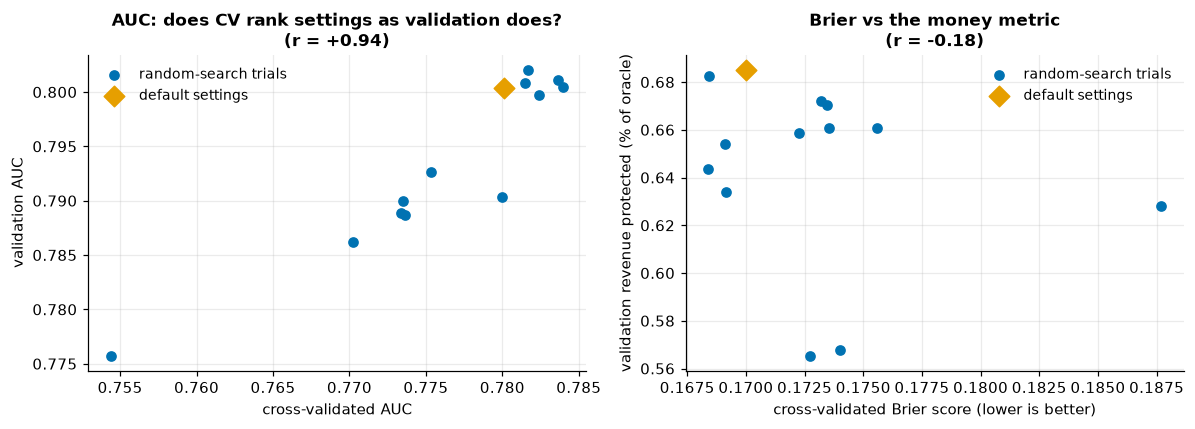

correlation, CV AUC vs validation AUC: +0.94;  CV Brier vs validation revenue protected: -0.18;  CV AUC vs validation revenue protected: -0.13


In [6]:
default_row = log.table().query("name == 'boosting, defaults'").iloc[0]
r_auc = trials["metric.cv_auc"].corr(trials["metric.val_auc"])
r_brier = trials["metric.cv_brier"].corr(trials["metric.val_revenue_pct_oracle"])

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.0))
for ax, x, y, xl, yl, r, t in [(a, "metric.cv_auc", "metric.val_auc", "cross-validated AUC", "validation AUC", r_auc, "AUC: does CV rank settings as validation does?"),
                               (b, "metric.cv_brier", "metric.val_revenue_pct_oracle", "cross-validated Brier score (lower is better)", "validation revenue protected (% of oracle)", r_brier, "Brier vs the money metric")]:
    ax.scatter(trials[x], trials[y], color=style.BLUE, label="random-search trials", zorder=3)
    ax.scatter([default_row[x]], [default_row[y]], color=style.ORANGE, s=90, marker="D", label="default settings", zorder=4)
    ax.set(xlabel=xl, ylabel=yl, title=f"{t}\n(r = {r:+.2f})"); ax.legend(loc="best")
plt.tight_layout(); plt.show()
r_auc_money = trials['metric.cv_auc'].corr(trials['metric.val_revenue_pct_oracle'])
print(f"correlation, CV AUC vs validation AUC: {r_auc:+.2f};  CV Brier vs validation revenue protected: {r_brier:+.2f};  CV AUC vs validation revenue protected: {r_auc_money:+.2f}")
assert r_auc > 0.8                                  # CV agrees with validation on ranking quality
assert abs(r_brier) < 0.5 and abs(r_auc_money) < 0.5   # but neither predicts the money metric

**Reading the charts.**

- **Left: cross-validation ranks settings the way validation does** (a correlation near 0.94). Choosing by CV was a sound use of the training data for *ranking quality*; we never had to spend the validation set on the search. The good settings cluster at the top right with the default among them, and the worst (deep trees fitted for many rounds, which overfit) lose roughly three hundredths of AUC. Search helps most by **steering us away from bad regions**.
- **Right: but the money metric is a different animal.** Across the same twelve settings, neither CV Brier score nor CV AUC predicts how much **revenue** a setting protects on validation (correlations of about −0.18 and −0.13, i.e. close to nothing). Revenue@200 depends on whether a handful of giant customers land in the top 200, and that swings from setting to setting in ways smooth metrics like AUC cannot see.

So a setting that wins on a proxy can lose on the thing we actually care about. We check the decision metric before adopting anything:

In [7]:
v = valid["monetary"].to_numpy()
pick_by_auc = trials.sort_values("metric.cv_auc", ascending=False).iloc[0]
pick_by_brier = trials.sort_values("metric.cv_brier", ascending=True).iloc[0]
probs_of = lambda row: trial_probs[int(row["name"].split()[-1])]

def compare(label, pa, pb):
    auc = bootstrap_difference(valid["y"], v, 1 - pa, 1 - pb, metric="AUC", n_boot=300, seed=0)
    rev = bootstrap_difference(valid["y"], v, (1 - pa) * v, (1 - pb) * v, metric="revenue@200", n_boot=300, seed=0)
    return {"comparison": label, "AUC difference [90% interval]": f"{auc['mean']:+.4f} [{auc['low']:+.4f}, {auc['high']:+.4f}]",
            "revenue@200 difference [90% interval]": f"{rev['mean']:+,.0f} [{rev['low']:+,.0f}, {rev['high']:+,.0f}]",
            "_auc_low": auc["low"], "_rev_low": rev["low"], "_rev_high": rev["high"]}

print(f"picked by CV AUC:   {pick_by_auc['name']}   |   picked by CV Brier: {pick_by_brier['name']}")
rows = [compare("picked by CV AUC vs default boosting", probs_of(pick_by_auc), p_boost_default),
        compare("picked by CV Brier vs default boosting", probs_of(pick_by_brier), p_boost_default),
        compare("picked by CV Brier vs logistic champion", probs_of(pick_by_brier), p_logistic),
        compare("default boosting vs logistic champion", p_boost_default, p_logistic)]
cmp_table = pd.DataFrame(rows)
cmp_table[["comparison", "AUC difference [90% interval]", "revenue@200 difference [90% interval]"]].set_index("comparison")

picked by CV AUC:   boosting, trial 09   |   picked by CV Brier: boosting, trial 09


,AUC difference [90% interval],revenue@200 difference [90% interval]
comparison,,
picked by CV AUC vs default boosting,"+0.0002 [-0.0035, +0.0041]","-41,635 [-70,777, -15,244]"
picked by CV Brier vs default boosting,"+0.0002 [-0.0035, +0.0041]","-41,635 [-70,777, -15,244]"
picked by CV Brier vs logistic champion,"+0.0043 [+0.0009, +0.0081]","-18,831 [-41,024, +2,250]"
default boosting vs logistic champion,"+0.0041 [-0.0016, +0.0096]","+22,804 [-7,209, +49,826]"


**Reading the comparison.** Choosing by CV AUC and choosing by CV Brier score both pick the **same** setting (trial 09), which has the best cross-validated scores on both. Against the default boosting model, that setting is no better at ranking (AUC difference about +0.0002, interval around zero) and **worse for money**: roughly £42,000 less revenue protected, with an interval that stays below zero. Against the logistic champion it ranks slightly better (+0.004, interval just above zero) but does not protect more revenue (about −£19,000, interval spanning zero).

Two cautions on how far to trust this.

- **These intervals only know about which customers were in the snapshot.** They say nothing about whether a different month would rank the settings the same way. With heavy-tailed revenue and a single snapshot, read the money differences as a *warning*, not a measurement.
- **The process worked.** Because we compared on the decision metric *before* adopting the tuned model, the proxy-metric winner was caught. Had we shipped on "best CV score" alone, we would have shipped the worse model for the business.

In [8]:
tuned_clearly_better = bool(cmp_table.loc[2, "_auc_low"] > 0 and cmp_table.loc[2, "_rev_low"] > 0)
FINAL = "tuned gradient boosting" if tuned_clearly_better else "logistic regression (champion)"
print("Does the tuned challenger clearly beat the champion on BOTH AUC and revenue?", tuned_clearly_better)
print("Final model:", FINAL)
assert not tuned_clearly_better                 # the decision recorded in the text below
assert cmp_table.loc[0, "_rev_high"] < 0       # and the warning above: the proxy-metric winner was worse for money

Does the tuned challenger clearly beat the champion on BOTH AUC and revenue? False
Final model: logistic regression (champion)


**Decision.** No boosting model, tuned or default, is clearly better than the logistic regression on both ranking and money, so by the simplest-within-noise rule **the logistic regression is our final model**. (The decision is computed from the intervals, so if the data ever changed it would be re-derived, not left to our memory.)

This is the typical shape of tuning on a noisy problem: a lot of compute, a clearer map of which settings to avoid, **no real gain over a sensible default**, and one cautionary tale about optimising a proxy. None of that is a failure. It is information, and it says the limit sits in the inputs, as the learning curve already suggested.

## Stop on purpose

Tuning has no natural end, so decide the budget **before** you start: how many trials, how much time, and what improvement would be worth shipping. Here, twelve trials plus two cheap hypotheses was plenty, and the log lets anyone see exactly what was tried.

<div class="admonition tip">
<p class="admonition-title">What the log buys you</p>
<ul>
<li><strong>Reproducibility:</strong> data fingerprint + seed + library versions + code commit recreate any run.</li>
<li><strong>Honesty about the search:</strong> the number of trials is on record, so an "improvement" can be judged against how hard we looked for it.</li>
<li><strong>Negative results kept:</strong> the refuted overdue-cap idea is documented, so nobody repeats it.</li>
</ul>
</div>

## Check yourself

<details class="question">
<summary>1. Why choose the winning setting by cross-validation on training data rather than by validation score?</summary>

Each setting you score on the validation set uses up a little of its honesty: pick the best of many and its score is optimistically biased. By choosing on training-data CV, the validation set stays an independent check that the choice generalises. Our scatter plot showed the two agree, which is what makes this safe.

</details>

<details class="question">
<summary>2. The overdue-cap experiment found nothing. Was it wasted?</summary>

No. It tested a specific, evidence-based hypothesis and refuted it cheaply, and the result is in the log. A project that only records successes cannot tell "we tried and it did not help" from "we never tried".

</details>

<details class="question">
<summary>3. A colleague says: 'We tried 200 settings, and the best has validation AUC 0.805, so the model gets 0.805.' What is wrong?</summary>

The 0.805 was selected for being the highest of 200 noisy numbers, so it overstates what a fresh sample would show (the winner's curse). The honest estimate comes from data not used in the selection: choose by CV, and quote the score of the *chosen* model on an untouched set, with an interval, as we did.

</details>

## Exercise

<details class="question">
<summary>How many of the twelve random-search trials beat the default boosting model's <em>validation</em> AUC by more than 0.003? Guess first, then count from the log.</summary>

```python
t = log.table()
default_auc = t.loc[t["name"] == "boosting, defaults", "metric.val_auc"].iloc[0]
trials_only = t[t["name"].str.contains("trial")]
print((trials_only["metric.val_auc"] > default_auc + 0.003).sum(), "of", len(trials_only))
```

None of them: the best trial's validation AUC is within about 0.002 of the default's, inside the noise. Random search found **no improvement** over the defaults, only settings that are worse. That is the usual outcome when the defaults are sensible and the signal is limited.

</details>

## Recap

- Tuning is a search, and every look at validation data spends some of its honesty. **Choose on training-data cross-validation** (grouped by customer), and use validation to confirm.
- **Log every run**: parameters, metrics, data fingerprint, seed, code and library versions. Keep negative results.
- Test **specific hypotheses** from your error analysis before a broad search. Here they were refuted, which is a result.
- **A winner on a proxy metric can lose on the decision metric.** CV AUC and Brier did not predict revenue protected, and the setting both chose was worse for money. Always check the metric you actually care about, and remember a single snapshot makes it noisy.
- Search steers you away from bad regions far more than it finds big gains. A sensible default is hard to beat on a noisy problem.
- Decide your tuning budget up front, compare the winner **paired**, and prefer the simpler model unless the gain is clear.

**Next:** *Interpretation and fairness*, where we ask what the final model has actually learned, and whether it treats groups of customers consistently.